# 07 — Evolução da associação ajustada pelo ATO | SP capital, 2014–2024
**IPT · Mestrado em Computação Aplicada · Big Data & Analytics**

Associação entre início do pré-natal e baixo peso ao nascer, ajustada pelas covariáveis observadas. **As estimativas não são efeitos causais identificados.** Onze modelos anuais independentes, mantendo a especificação principal do [notebook 06](06_ato_sp_capital_2024.ipynb).

Execute com a **`.venv` deste projeto**: no PowerShell, a partir da raiz do projeto, `& .\.venv\Scripts\Activate.ps1`; selecione esse ambiente como kernel Jupyter. O notebook lê somente bases locais e não grava arquivos auxiliares, baixa dados ou instala pacotes.

## Resumo executivo

**A direção da associação ajustada é persistente: negativa nos onze anos. A magnitude oscila, sem tendência monotônica.** O ATO varia de **−0,58 p.p. (2020)** a **−1,90 p.p. (2023)**. Em **2024, −1,74 p.p.** reproduz a referência anterior e fica próximo de 2021 (−1,73) e 2022 (−1,77), sem evidência nesta etapa de diferença estatisticamente significativa entre anos.

- T=0 cai de **24.348 (14,76%)** em 2014 para **10.118 (8,82%)** em 2024; os elegíveis passam de 164.987 para 114.694.
- Todos os ajustes convergiram. Maior |SMD| nas covariáveis ajustadas: **0,0070**, em 2020. Situação conjugal, fora do modelo, conserva desequilíbrio em todos os anos (máximo anual entre **0,184 e 0,207**).
- Não há colapso do ESS por ponderação: retenção mínima de **77,4% em T=1** e **99,2% em T=0**. Entretanto, **2024 tem os menores ESS absolutos dos dois grupos: 84.995 e 10.096**; a redução de T=0 merece atenção na avaliação futura da precisão.
- A maior massa de pesos fora do suporte empírico comum é **0,0329% (2023, T=1)**. Não houve impedimento de estimação nem recorte automático.

As populações de sobreposição podem mudar ao longo dos anos. Estes resultados são **associações observacionais**, sem IC anual ou teste de mudança temporal nesta etapa. Três registros de idade receberam a imputação prevista no pipeline, com autorização manual e sem exclusões.

## 1. Contexto e metodologia

**Pergunta:** a direção e a magnitude da associação ajustada se mantêm entre 2014 e 2024? A finalidade é comparação descritiva entre estimativas anuais, sem recomendar intervenção clínica.

| Elemento | Especificação preservada |
|---|---|
| Unidade / chave | Registro de nascido vivo; chave `(ano, contador)`, única dentro de cada arquivo anual. Não identifica mães longitudinalmente. |
| População | Residência materna `CODMUNRES=355030`, gestação única, peso de 500 a 6.000 g, início do pré-natal nos meses 1–6. |
| Exposição / comparação | T=1: início nos meses 1–3; T=0: meses 4–6. T=0 não significa ausência de pré-natal. |
| Desfecho | Y=1 se peso ao nascer <2.500 g, medido no parto, após a classificação do início do pré-natal. |
| Covariáveis | Idade (10–59) e idade²; escolaridade; raça/cor; paridade; perdas fetais anteriores. |
| Fora do modelo | Situação conjugal (somente diagnóstico); peso, consultas, idade gestacional, tipo de parto, Apgar, Kotelchuck, Robson e demais variáveis posteriores. |
| Escore | Logística L2, C=1, `lbfgs`, 500 iterações, tolerância 1e-5, sem pesos de classe, ajustada na amostra inteira de cada ano. |
| Pesos ATO | T=1: 1−e(X); T=0: e(X). Riscos normalizados dentro de cada grupo. Diferença = 100 × (risco T=1 − risco T=0), em p.p. |
| ESS | Tamanho efetivo de Kish: (Σw)²/Σw², por grupo. Não equivale a poder estatístico. |

### Codificação e ausentes

Reutilizam-se `src.amostra._criar_views` e `src.diagnosticos.construir_pipeline_propensity`, sem modificar esses arquivos. Escolaridade e raça/cor: 9/nulo → `IGNORADO`; paridade: 9/99/nulo → `IGNORADO`; perdas fetais: 0, 1, 2–98 → `2_OU_MAIS`, demais valores → `IGNORADO`. Categóricas recebem indicadores e imputação modal residual prevista no pipeline. Não se redefine a codificação para melhorar resultados.

**Exceção validada pelo usuário em 23/10/2026:** uma idade fora de 10–59 em cada ano de 2017 (60), 2022 (62) e 2023 (61). Esses registros são mantidos. Idade e idade² tornam-se ausentes e recebem, separadamente, a mediana anual e indicadores de ausência, conforme o pipeline original. O notebook 06 não precisou dessa imputação em 2024; seu bloqueio de idade ausente é relaxado somente para os três casos validados. O balanço considera os termos imputados e os indicadores.

### Hipóteses e temporalidade

A janela conceitual das covariáveis é anterior ao início do pré-natal; características registradas no parto são aproximações, e sua disponibilidade naquele momento não é demonstrada. Não há decisão prospectiva observada nem randomização. O contraste é entre nascidos vivos elegíveis no mesmo ano. Interpretação causal exigiria hipóteses adicionais não demonstradas de consistência, comparabilidade condicional, positividade e mensuração adequada.

A parte **descritiva** traz contagens e riscos brutos; a parte **ajustada observacional** usa o escore para ponderação. Não há modelo preditivo de desfecho. Não são executados bootstrap, sensibilidades, trimming, matching ou modelo combinado entre anos.

In [1]:
from pathlib import Path
from datetime import datetime
from zoneinfo import ZoneInfo
import sys, json, base64, hashlib, warnings
sys.dont_write_bytecode = True
import duckdb
import numpy as np
import pandas as pd
import sklearn
import plotly
import plotly.graph_objects as go
import plotly.io as pio
from sklearn.exceptions import ConvergenceWarning
from IPython.display import display, Markdown

cwd = Path.cwd().resolve()
raiz = next(p for p in [cwd, *cwd.parents]
            if (p / "src/visualizacao.py").is_file() and (p / "data/processed").is_dir())
if str(raiz) not in sys.path:
    sys.path.insert(0, str(raiz))
from src.amostra import _criar_views
from src.diagnosticos import construir_pipeline_propensity, validar_colunas_propensity
from src.visualizacao import CORES_IPT, aplicar_tema_base

ANOS = list(range(2014, 2025))
MUNICIPIO = "355030"
NUMERICAS = ["IDADEMAE_NUM", "IDADEMAE_QUAD"]
CATEGORICAS = ["ESCOLARIDADE_MAE", "RACA_COR_MAE", "PARIDADE_CAT", "PERDAS_FETAIS_CAT"]
IDADES_AUTORIZADAS = {2017: [60.0], 2022: [62.0], 2023: [61.0]}
validar_colunas_propensity([*NUMERICAS, *CATEGORICAS])
assert "SITUACAO_CONJUGAL" not in NUMERICAS + CATEGORICAS

def fmt(valor, casas=0):
    if pd.isna(valor):
        return "—"
    return f"{valor:,.{casas}f}".replace(",", "§").replace(".", ",").replace("§", ".")

def tabela_ipt(tabela, casas=None):
    casas = casas or {}
    formatos = {c: (lambda v, d=casas.get(c, 0): fmt(v, d))
                for c in tabela.select_dtypes(include="number")}
    return (tabela.style.format(formatos, na_rep="—")
        .set_table_styles([
            {"selector": "th", "props": [("background-color", CORES_IPT["AZUL_PRINCIPAL"]),
                ("color", "white"), ("padding", "7px")]},
            {"selector": "td", "props": [("padding", "6px 9px"),
                ("border-bottom", "1px solid #D9E7EE")]},
            {"selector": "table", "props": [("font-family", "Arial"), ("font-size", "13px")]},
        ]))

def exibir_plotly(figura):
    png = figura.to_image(format="png", scale=1.5)
    display({"application/vnd.plotly.v1+json": json.loads(pio.to_json(figura)),
             "image/png": base64.b64encode(png).decode("ascii"),
             "text/plain": figura.layout.title.text}, raw=True)

print("Ambiente:", sys.executable)
print("Versões: DuckDB", duckdb.__version__, "| pandas", pd.__version__,
      "| NumPy", np.__version__, "| scikit-learn", sklearn.__version__, "| Plotly", plotly.__version__)
print("Execução:", datetime.now(ZoneInfo("America/Sao_Paulo")).isoformat(timespec="seconds"))

Ambiente: C:\GitHub\data-science-projects\projetos\big-data-sinasc-causal-ml\.venv\Scripts\python.exe
Versões: DuckDB 1.5.5 | pandas 3.0.6 | NumPy 2.4.6 | scikit-learn 1.8.0 | Plotly 6.9.0
Execução: 2026-10-23T14:52:56-03:00


## 2. Fontes e verificações anteriores à estimação

Fontes e contagens esperadas vêm do [diagnóstico histórico concluído](05a_qualidade_geografica_sp_2014_2024.ipynb) e de seu [CSV existente](../../outputs/qualidade_geografica_2024/qualidade_sp_por_ano.csv). Ele já verificou os onze anos de nascimento e a qualidade dos campos. Não se repete essa auditoria.

Verificações limitadas ao contrato desta análise: arquivo e campos disponíveis, contagens reconciliadas, chave única, ano correto nos elegíveis, T/Y e covariáveis compatíveis. Não se excluem registros por covariáveis. Ano com impedimento fica documentado sem estimativa ajustada e sem alteração automática do método.

In [2]:
arquivo_referencia = raiz / "outputs/qualidade_geografica_2024/qualidade_sp_por_ano.csv"
referencia = pd.read_csv(arquivo_referencia, sep=";")
referencia = referencia.loc[referencia.recorte_id.eq("sp_capital")].set_index("ano").sort_index()
assert referencia.index.is_unique and referencia.index.tolist() == ANOS
fontes = {ano: raiz / referencia.loc[ano, "fonte"] for ano in ANOS}
assert all(p.is_file() for p in fontes.values()), "Base local referenciada ausente."
arquivos_metodo = ["notebooks/principal/06_ato_sp_capital_2024.ipynb",
    "notebooks/principal/05a_qualidade_geografica_sp_2014_2024.ipynb",
    "outputs/qualidade_geografica_2024/qualidade_sp_por_ano.csv",
    "src/amostra.py", "src/diagnosticos.py", "src/visualizacao.py"]
assinaturas = {f: hashlib.sha256((raiz / f).read_bytes()).hexdigest() for f in arquivos_metodo}
proveniencia = pd.DataFrame([{"Ano": ano, "Fonte local": p.relative_to(raiz).as_posix(),
    "Bytes": p.stat().st_size, "Elegíveis esperados": int(referencia.loc[ano, "n_elegiveis"])}
    for ano, p in fontes.items()]).set_index("Ano")
display(tabela_ipt(proveniencia))

,Fonte local,Bytes,Elegíveis esperados
Ano,,,
2014,data/processed/sinasc/sinasc_2014.parquet,69.465.734,164.987
2015,data/processed/sinasc/sinasc_2015.parquet,69.918.843,165.787
2016,data/processed/sinasc/sinasc_2016.parquet,70.972.289,158.025
2017,data/processed/sinasc/sinasc_2017.parquet,68.236.897,160.429
2018,data/processed/sinasc/sinasc_2018.parquet,67.945.500,156.806
2019,data/processed/sinasc/sinasc_2019.parquet,65.457.805,150.427
2020,data/processed/sinasc/sinasc_2020.parquet,63.126.678,139.283
2021,data/processed/sinasc/sinasc_2021.parquet,61.983.638,129.761
2022,data/processed/sinasc/sinasc_2022.parquet,58.557.616,125.306


In [3]:
def exigir(condicao, mensagem):
    if not condicao:
        raise ValueError(mensagem)

def carregar_ano(ano):
    """Mesma projeção e filtros do 06; estabiliza somente nomes das saídas."""
    with duckdb.connect() as con:
        con.execute("SET threads=4")
        _criar_views(con, fontes[ano])
        sql = con.execute("SELECT sql FROM duckdb_views() WHERE view_name='amostra_principal'").fetchone()[0]
        projecao = sql[sql.index(" AS SELECT ") + 4:sql.index(" FROM fase1_base")]
        dados = con.execute(
            projecao
            + ", mesprenat_num, peso_num, gravidez_num, CAST(CODMUNRES AS VARCHAR) AS municipio"
            + ", year(try_strptime(CAST(DTNASC AS VARCHAR), '%d%m%Y')) AS ano_nascimento"
            + ", try_cast(IDADEMAE AS DOUBLE) AS idade_bruta"
            + " FROM fase1_base WHERE tratamento IS NOT NULL AND y_p1 IS NOT NULL"
            + " AND gravidez_num=1 AND mesprenat_num BETWEEN 1 AND 6"
            + " AND CAST(CODMUNRES AS VARCHAR)=? ORDER BY contador", [MUNICIPIO]).df()
    # DuckDB lê nomes sem distinção de caixa; CONTADOR varia entre arquivos.
    dados = dados.rename(columns={c: "contador" for c in dados if c.lower() == "contador"})
    exigir(not dados.empty, "Nenhum nascimento elegível.")
    exigir(dados.contador.notna().all() and dados.contador.is_unique, "Chave contador inválida.")
    exigir(dados.ano_nascimento.notna().all() and dados.ano_nascimento.eq(ano).all(), "Data fora do ano/inválida.")
    exigir(dados.municipio.eq(MUNICIPIO).all() and dados.gravidez_num.eq(1).all(), "População incompatível.")
    exigir(dados.peso_num.between(500, 6000).all(), "Peso fora da especificação.")
    dados["tratamento"] = dados.tratamento.astype(int)
    dados["Y_BAIXO_PESO"] = dados.Y_BAIXO_PESO.astype(int)
    exigir(set(dados.tratamento) == {0, 1}, "Tratamento ou comparação ausente.")
    exigir(dados.tratamento.eq(dados.mesprenat_num.le(3).astype(int)).all(), "T incompatível.")
    exigir(dados.Y_BAIXO_PESO.eq(dados.peso_num.lt(2500).astype(int)).all(), "Y incompatível.")
    contagens = [len(dados), int(dados.tratamento.sum()), int(dados.tratamento.eq(0).sum())]
    exigir(contagens == referencia.loc[ano, ["n_elegiveis", "n_t1", "n_t0"]].astype(int).tolist(),
           "Contagens divergem do diagnóstico histórico; revisar implementação.")
    dados["IDADEMAE_QUAD"] = dados.IDADEMAE_NUM ** 2
    ausentes = dados.loc[dados.IDADEMAE_NUM.isna(), "idade_bruta"].sort_values().tolist()
    exigir(ausentes == IDADES_AUTORIZADAS.get(ano, []), "Idades ausentes não autorizadas; validar manualmente.")
    exigir(dados[CATEGORICAS + ["SITUACAO_CONJUGAL"]].notna().all().all(),
           "Ausência categórica residual não prevista; validar manualmente.")
    return dados

### Cálculo e teste das fórmulas

Os testes pequenos verificam o sentido T=1−T=0, a normalização dentro dos grupos e o ESS. São verificações de implementação, sem novos experimentos sobre os dados.

In [4]:
def medidas_ato(t, y, e):
    w = np.where(t == 1, 1 - e, e)
    exigir(np.isfinite(e).all() and ((e >= 0) & (e <= 1)).all(), "Escore inválido.")
    saida = {"w": w}
    for g in (1, 0):
        mask = t == g
        wg = w[mask]
        exigir(mask.sum() > 1 and wg.sum() > 0, f"Grupo T={g} sem massa de ponderação.")
        saida[f"r{g}"] = np.average(y[mask], weights=wg)
        saida[f"ess{g}"] = wg.sum() ** 2 / np.square(wg).sum()
        saida[f"soma_w{g}"] = wg.sum()
        saida[f"soma_wy{g}"] = (wg * y[mask]).sum()
    saida["dif_ato_pp"] = 100 * (saida["r1"] - saida["r0"])
    return saida

# Exemplo conhecido à mão: pesos (0,2; 0,4; 0,4; 0,2), riscos 1/3 e 2/3.
checagem = medidas_ato(np.array([0, 0, 1, 1]), np.array([0, 1, 0, 1]),
                      np.array([0.2, 0.4, 0.6, 0.8]))
np.testing.assert_allclose([checagem["r1"], checagem["r0"], checagem["dif_ato_pp"],
                            checagem["ess1"], checagem["ess0"]], [1/3, 2/3, -100/3, 1.8, 1.8])
try:
    validar_colunas_propensity(["IDADEMAE_NUM", "Y_BAIXO_PESO"])
except ValueError:
    pass
else:
    raise AssertionError("O bloqueio de leakage deveria rejeitar Y no escore.")
print("Fórmulas de risco/ESS e bloqueio de leakage conferidos.")

Fórmulas de risco/ESS e bloqueio de leakage conferidos.


### Balanço e suporte: critérios preservados

SMD usa o desvio-padrão combinado **não ponderado**, fixo antes/depois; categóricas são avaliadas nível a nível. Nos anos com imputação, idade e idade² são avaliadas nas escalas imputadas, antes da padronização, incluindo seus indicadores de ausência. O máximo das covariáveis ajustadas resume os termos efetivamente usados pelo modelo.

Situação conjugal e indicador de adolescência (idade observada ≤19) são diagnósticos separados, fora do modelo. Para SMD, 0,1 e 0,2 são referências descritivas convencionais, sem teste de significância. Balanço pequeno nos termos ajustados é esperado com escore logístico e pesos ATO; a penalização torna-o aproximado.

Suporte comum = interseção dos intervalos observados do escore nos dois grupos. Registra-se a fração da massa de pesos fora desse intervalo e o maior peso relativo individual. Suporte empírico não comprova positividade condicional. Nenhum recorte é aplicado.

In [5]:
def calcular_balanco(dados, t, w, modelo):
    termos = {}
    imputador = modelo["preprocessamento"].named_transformers_["numericas"]["imputa"]
    valores = imputador.transform(dados[NUMERICAS])
    nomes = list(imputador.get_feature_names_out(NUMERICAS))
    for j, nome in enumerate(nomes):
        termos[(nome, "termo", True)] = valores[:, j]
    for coluna in CATEGORICAS + ["SITUACAO_CONJUGAL"]:
        for nivel in sorted(dados[coluna].unique()):
            termos[(coluna, nivel, coluna in CATEGORICAS)] = dados[coluna].eq(nivel).to_numpy(float)
    termos[("ADOLESCENTE_OBSERVADA", "10–19 anos", False)] = dados.IDADEMAE_NUM.le(19).to_numpy(float)
    linhas = []
    for (variavel, nivel, ajustada), v in termos.items():
        v1, v0 = v[t == 1], v[t == 0]
        dp = np.sqrt((v1.var(ddof=1) + v0.var(ddof=1)) / 2)
        m1, m0 = np.average(v1, weights=w[t == 1]), np.average(v0, weights=w[t == 0])
        linhas.append({"variavel": variavel, "nivel": nivel, "ajustada": ajustada,
            "smd_antes": (v1.mean() - v0.mean()) / dp if dp else 0.0,
            "smd_depois": (m1 - m0) / dp if dp else 0.0})
    return pd.DataFrame(linhas)

def ajustar_ano(ano, dados):
    x = dados[NUMERICAS + CATEGORICAS]
    validar_colunas_propensity(x.columns)
    t, y = dados.tratamento.to_numpy(int), dados.Y_BAIXO_PESO.to_numpy(int)
    modelo = construir_pipeline_propensity(NUMERICAS, CATEGORICAS)
    with warnings.catch_warnings(record=True) as avisos:
        warnings.simplefilter("always")
        modelo.fit(x, t)
    mensagens = [f"{a.category.__name__}: {a.message}" for a in avisos]
    exigir(not any(issubclass(a.category, ConvergenceWarning) for a in avisos),
           "Escore não convergiu: " + "; ".join(mensagens))
    e = modelo.predict_proba(x)[:, 1]
    medidas = medidas_ato(t, y, e)
    w = medidas.pop("w")
    e1, e0 = e[t == 1], e[t == 0]
    inferior, superior = max(e1.min(), e0.min()), min(e1.max(), e0.max())
    exigir(inferior < superior, "Ausência de intervalo de suporte empírico comum.")
    fora = (e < inferior) | (e > superior)
    bal = calcular_balanco(dados, t, w, modelo)
    bal.insert(0, "ano", ano)
    ajustadas = bal.loc[bal.ajustada]
    conjugal = bal.loc[bal.variavel.eq("SITUACAO_CONJUGAL")]
    adolescente = bal.loc[bal.variavel.eq("ADOLESCENTE_OBSERVADA")]
    diag = {"ano": ano, "iteracoes": int(modelo["modelo"].n_iter_.max()),
        "idade_imputada": int(dados.IDADEMAE_NUM.isna().sum()),
        "media_e": e.mean(), "prop_t1": t.mean(),
        "suporte_min": inferior, "suporte_max": superior,
        "smd_antes_max": ajustadas.smd_antes.abs().max(),
        "smd_depois_max": ajustadas.smd_depois.abs().max(),
        "n_smd_acima_01": int(ajustadas.smd_depois.abs().gt(0.1).sum()),
        "smd_conjugal_max": conjugal.smd_depois.abs().max(),
        "smd_adolescente": adolescente.smd_depois.abs().max(),
        "avisos": "; ".join(mensagens) or "Nenhum"}
    for g in (1, 0):
        mask = t == g
        diag.update({f"fora_n_t{g}": int((fora & mask).sum()),
            f"fora_peso_t{g}_pct": 100 * w[fora & mask].sum() / w[mask].sum(),
            f"max_participacao_t{g}_pct": 100 * w[mask].max() / w[mask].sum(),
            f"e_min_t{g}": e[mask].min(), f"e_max_t{g}": e[mask].max(),
            f"ess_rel_t{g}_pct": 100 * medidas[f"ess{g}"] / mask.sum()})
    return medidas, diag, bal

## 3. Estimações anuais

Primeiro é conciliado 2024 com as contagens, os casos de baixo peso e as estimativas publicadas no notebook 06. A tolerância de 0,005 p.p. corresponde ao arredondamento da referência a duas casas. Divergência material interrompe a execução antes dos demais ajustes. O IC anterior (−2,36 a −1,12 p.p.) é referência documental; não é recalculado nem estendido aos outros anos.

In [6]:
linhas_resultados, linhas_diagnosticos, balancos = [], [], []
# 2024 primeiro: conciliar a implementação antes de ajustar a série.
for ano in [2024] + ANOS[:-1]:
    linha = {"ano": ano, "status": "Não estimado", "impedimento": ""}
    try:
        dados = carregar_ano(ano)
        t, y = dados.tratamento.to_numpy(int), dados.Y_BAIXO_PESO.to_numpy(int)
        linha.update(n=len(dados), n_t1=int((t == 1).sum()), n_t0=int((t == 0).sum()),
            pct_t0=100 * (t == 0).mean(), casos_t1=int(y[t == 1].sum()), casos_t0=int(y[t == 0].sum()),
            risco_bruto_t1_pct=100 * y[t == 1].mean(), risco_bruto_t0_pct=100 * y[t == 0].mean(),
            dif_bruta_pp=100 * (y[t == 1].mean() - y[t == 0].mean()))
        medidas, diagnostico, bal = ajustar_ano(ano, dados)
        linha.update({k: v for k, v in medidas.items() if k not in ["r1", "r0"]})
        linha.update(risco_ato_t1_pct=100 * medidas["r1"], risco_ato_t0_pct=100 * medidas["r0"], status="Estimado")
        if ano == 2024:
            assert [linha["n"], linha["n_t1"], linha["n_t0"]] == [114694, 104576, 10118]
            assert [linha["casos_t1"], linha["casos_t0"]] == [8797, 1053]
            np.testing.assert_allclose([linha["dif_bruta_pp"], linha["dif_ato_pp"]], [-2.00, -1.74], atol=0.005, rtol=0)
            np.testing.assert_allclose([linha["risco_ato_t1_pct"], linha["risco_ato_t0_pct"]], [8.68, 10.42], atol=0.005, rtol=0)
        linhas_diagnosticos.append(diagnostico)
        balancos.append(bal)
    except (ValueError, duckdb.Error, FileNotFoundError) as erro:
        linha["status"] = "Não estimado"
        linha["impedimento"] = str(erro)
        if ano == 2024:
            raise RuntimeError("Conciliar 2024 antes de prosseguir: " + str(erro)) from erro
    linhas_resultados.append(linha)
    print(f"{ano}: {linha['status']} | n={fmt(linha.get('n', np.nan))} | "
          f"ATO={fmt(linha.get('dif_ato_pp', np.nan), 3)} p.p." +
          (f" | {linha['impedimento']}" if linha['impedimento'] else ""))

resultados = pd.DataFrame(linhas_resultados).set_index("ano").reindex(ANOS)
diagnosticos = pd.DataFrame(linhas_diagnosticos).set_index("ano").reindex(ANOS)
balanco = pd.concat(balancos, ignore_index=True)
resultados.index.name = diagnosticos.index.name = "Ano"
validos = resultados.status.eq("Estimado")
assert resultados.index.is_unique and len(resultados) == 11
assert (resultados.loc[validos, "n"] == resultados.loc[validos, "n_t1"] + resultados.loc[validos, "n_t0"]).all()
for g in (1, 0):
    np.testing.assert_allclose(resultados.loc[validos, f"risco_bruto_t{g}_pct"],
        100 * resultados.loc[validos, f"casos_t{g}"] / resultados.loc[validos, f"n_t{g}"])
    np.testing.assert_allclose(resultados.loc[validos, f"risco_ato_t{g}_pct"],
        100 * resultados.loc[validos, f"soma_wy{g}"] / resultados.loc[validos, f"soma_w{g}"])
    assert (resultados.loc[validos, f"ess{g}"] <= resultados.loc[validos, f"n_t{g}"] + 1e-8).all()
np.testing.assert_allclose(resultados.loc[validos, "dif_ato_pp"],
    resultados.loc[validos, "risco_ato_t1_pct"] - resultados.loc[validos, "risco_ato_t0_pct"])
print("Conciliação de 2024 e identidades de cálculo conferidas; nenhum bootstrap executado.")

2024: Estimado | n=114.694 | ATO=-1,737 p.p.


2014: Estimado | n=164.987 | ATO=-1,107 p.p.


2015: Estimado | n=165.787 | ATO=-0,987 p.p.


2016: Estimado | n=158.025 | ATO=-1,079 p.p.


2017: Estimado | n=160.429 | ATO=-1,567 p.p.


2018: Estimado | n=156.806 | ATO=-1,800 p.p.


2019: Estimado | n=150.427 | ATO=-1,189 p.p.


2020: Estimado | n=139.283 | ATO=-0,578 p.p.


2021: Estimado | n=129.761 | ATO=-1,727 p.p.


2022: Estimado | n=125.306 | ATO=-1,769 p.p.


2023: Estimado | n=122.244 | ATO=-1,903 p.p.
Conciliação de 2024 e identidades de cálculo conferidas; nenhum bootstrap executado.


### População e riscos brutos — descrição

Percentual T=0 usa todos os elegíveis do ano; riscos brutos usam os nascimentos do próprio grupo.

In [7]:
populacao = resultados[["n", "n_t1", "n_t0", "pct_t0", "risco_bruto_t1_pct", "risco_bruto_t0_pct", "dif_bruta_pp"]].rename(columns={
    "n": "Elegíveis", "n_t1": "T=1", "n_t0": "T=0", "pct_t0": "T=0 (%)",
    "risco_bruto_t1_pct": "Risco T=1 (%)", "risco_bruto_t0_pct": "Risco T=0 (%)", "dif_bruta_pp": "Dif. bruta (p.p.)"})
display(tabela_ipt(populacao, {c: 2 for c in populacao.columns[3:]}))

,Elegíveis,T=1,T=0,T=0 (%),Risco T=1 (%),Risco T=0 (%),Dif. bruta (p.p.)
Ano,,,,,,,
2014,164.987,140.639,24.348,"14,76","7,44","8,72","-1,28"
2015,165.787,141.442,24.345,"14,68","7,46","8,63","-1,17"
2016,158.025,136.923,21.102,"13,35","7,56","8,88","-1,32"
2017,160.429,141.470,18.959,"11,82","7,49","9,26","-1,77"
2018,156.806,138.992,17.814,"11,36","7,50","9,55","-2,05"
2019,150.427,132.846,17.581,"11,69","7,66","9,09","-1,43"
2020,139.283,123.840,15.443,"11,09","7,45","8,20","-0,75"
2021,129.761,117.056,12.705,"9,79","7,79","9,76","-1,97"
2022,125.306,112.936,12.370,"9,87","8,18","10,23","-2,06"


### Resultados ajustados e tamanho amostral efetivo

Os riscos e diferenças ATO referem-se à população de sobreposição de cada ano. ESS arredondado para leitura; cálculos mantêm precisão integral. Linhas sem ajuste são identificadas em “Estado da estimação”.

In [8]:
ajustados = resultados[["risco_ato_t1_pct", "risco_ato_t0_pct", "dif_ato_pp", "ess1", "ess0"]].rename(columns={
    "risco_ato_t1_pct": "Risco ATO T=1 (%)", "risco_ato_t0_pct": "Risco ATO T=0 (%)",
    "dif_ato_pp": "Dif. ATO (p.p.)", "ess1": "ESS T=1", "ess0": "ESS T=0"})
ajustados["ESS/n T=1 (%)"] = diagnosticos.ess_rel_t1_pct
ajustados["ESS/n T=0 (%)"] = diagnosticos.ess_rel_t0_pct
display(tabela_ipt(ajustados, {c: 2 for c in ajustados if c not in ["ESS T=1", "ESS T=0"]}))

,Risco ATO T=1 (%),Risco ATO T=0 (%),Dif. ATO (p.p.),ESS T=1,ESS T=0,ESS/n T=1 (%),ESS/n T=0 (%)
Ano,,,,,,,
2014,"7,61","8,72","-1,11",108.879,24.155,"77,42","99,21"
2015,"7,61","8,60","-0,99",110.184,24.153,"77,90","99,21"
2016,"7,80","8,88","-1,08",108.773,20.978,"79,44","99,41"
2017,"7,68","9,24","-1,57",112.037,18.879,"79,20","99,58"
2018,"7,75","9,55","-1,80",108.388,17.733,"77,98","99,55"
2019,"7,87","9,06","-1,19",106.088,17.509,"79,86","99,59"
2020,"7,62","8,20","-0,58",99.307,15.389,"80,19","99,65"
2021,"8,04","9,77","-1,73",92.163,12.666,"78,73","99,69"
2022,"8,46","10,23","-1,77",88.856,12.331,"78,68","99,68"


## 4. Diagnósticos essenciais

Máximos incluem todos os níveis categóricos presentes no ano. Situação conjugal não está no modelo principal; seu desequilíbrio residual não deve ser ocultado pelo bom balanço das variáveis ajustadas.

Nesta execução, nenhum ano apresenta |SMD| >0,1 nos termos ajustados. Situação conjugal apresenta máximo acima de 0,1 em todos os anos e acima de 0,2 em 2014 e 2019. O ESS não sofre colapso relativo; o menor volume efetivo em 2024, sobretudo T=0, é a preocupação para futura quantificação de precisão.

In [9]:
resumo_balanco = diagnosticos[["smd_antes_max", "smd_depois_max", "n_smd_acima_01", "smd_conjugal_max", "smd_adolescente"]].rename(columns={
    "smd_antes_max": "Máx. |SMD| antes", "smd_depois_max": "Máx. |SMD| ATO",
    "n_smd_acima_01": "Termos ATO >0,1", "smd_conjugal_max": "Conjugal |SMD| ATO",
    "smd_adolescente": "Adolescente |SMD| ATO"})
display(tabela_ipt(resumo_balanco, {c: 4 for c in resumo_balanco if c != "Termos ATO >0,1"}))

,Máx. |SMD| antes,Máx. |SMD| ATO,"Termos ATO >0,1",Conjugal |SMD| ATO,Adolescente |SMD| ATO
Ano,,,,,
2014,"0,5482","0,0022",0,"0,2026","0,0059"
2015,"0,5324","0,0010",0,"0,1839","0,0074"
2016,"0,5022","0,0010",0,"0,1908","0,0031"
2017,"0,5140","0,0027",0,"0,1898","0,0014"
2018,"0,5181","0,0036",0,"0,1991","0,0153"
2019,"0,4879","0,0030",0,"0,2066","0,0005"
2020,"0,4900","0,0070",0,"0,1953","0,0017"
2021,"0,5093","0,0016",0,"0,1943","0,0123"
2022,"0,5063","0,0044",0,"0,1997","0,0062"


In [10]:
# Máximo por covariável após ATO; níveis completos disponíveis em `balanco`.
nomes_cov = {"IDADEMAE_NUM": "Idade", "IDADEMAE_QUAD": "Idade²", "ESCOLARIDADE_MAE": "Escolaridade",
    "RACA_COR_MAE": "Raça/cor", "PARIDADE_CAT": "Paridade", "PERDAS_FETAIS_CAT": "Perdas fetais",
    "missingindicator_IDADEMAE_NUM": "Ausência idade", "missingindicator_IDADEMAE_QUAD": "Ausência idade²"}
por_covariavel = (balanco.loc[balanco.ajustada].assign(abs_smd=lambda x: x.smd_depois.abs())
    .pivot_table(index="ano", columns="variavel", values="abs_smd", aggfunc="max")
    .rename(columns=nomes_cov).reindex(ANOS))
por_covariavel.index.name = "Ano"
display(tabela_ipt(por_covariavel, {c: 4 for c in por_covariavel}))
print("Traço: termo de ausência não gerado no ano, pois não houve idade ausente.")

variavel,Escolaridade,Idade,Idade²,Paridade,Perdas fetais,Raça/cor,Ausência idade,Ausência idade²
Ano,,,,,,,,
2014,"0,0009","0,0001","0,0000","0,0000","0,0022","0,0006",—,—
2015,"0,0009","0,0001","0,0001","0,0001","0,0010","0,0005",—,—
2016,"0,0010","0,0001","0,0000","0,0001","0,0001","0,0003",—,—
2017,"0,0027","0,0001","0,0001","0,0000","0,0006","0,0015","0,0000","0,0000"
2018,"0,0025","0,0000","0,0000","0,0002","0,0036","0,0012",—,—
2019,"0,0014","0,0001","0,0001","0,0000","0,0030","0,0021",—,—
2020,"0,0070","0,0000","0,0001","0,0002","0,0002","0,0014",—,—
2021,"0,0015","0,0001","0,0000","0,0001","0,0016","0,0011",—,—
2022,"0,0009","0,0002","0,0000","0,0001","0,0044","0,0003","0,0000","0,0000"


Traço: termo de ausência não gerado no ano, pois não houve idade ausente.


In [11]:
suporte = diagnosticos[["suporte_min", "suporte_max", "fora_n_t1", "fora_n_t0", "fora_peso_t1_pct", "fora_peso_t0_pct"]].rename(columns={
    "suporte_min": "Suporte mín.", "suporte_max": "Suporte máx.", "fora_n_t1": "Fora T=1 (n)",
    "fora_n_t0": "Fora T=0 (n)", "fora_peso_t1_pct": "Peso fora T=1 (%)", "fora_peso_t0_pct": "Peso fora T=0 (%)"})
display(tabela_ipt(suporte, {c: 4 for c in suporte if "(n)" not in c}))

,Suporte mín.,Suporte máx.,Fora T=1 (n),Fora T=0 (n),Peso fora T=1 (%),Peso fora T=0 (%)
Ano,,,,,,
2014,"0,3240","0,9795",10,0,"0,0044","0,0000"
2015,"0,3428","0,9880",0,1,"0,0000","0,0014"
2016,"0,3938","0,9694",40,0,"0,0102","0,0000"
2017,"0,5020","0,9739",15,0,"0,0082","0,0000"
2018,"0,4415","0,9753",5,1,"0,0006","0,0020"
2019,"0,5907","0,9712",55,0,"0,0132","0,0000"
2020,"0,5014","0,9730",1,0,"0,0039","0,0000"
2021,"0,5557","0,9810",112,0,"0,0317","0,0000"
2022,"0,5875","0,9812",1,1,"0,0000","0,0053"


In [12]:
concentracao = diagnosticos[["media_e", "prop_t1", "max_participacao_t1_pct", "max_participacao_t0_pct", "iteracoes", "idade_imputada"]].rename(columns={
    "media_e": "Média e(X)", "prop_t1": "Proporção T=1", "max_participacao_t1_pct": "Máx. peso relativo T=1 (%)",
    "max_participacao_t0_pct": "Máx. peso relativo T=0 (%)", "iteracoes": "Iterações", "idade_imputada": "Idades imputadas"})
display(tabela_ipt(concentracao, {c: 4 for c in concentracao.columns[:4]}))

,Média e(X),Proporção T=1,Máx. peso relativo T=1 (%),Máx. peso relativo T=0 (%),Iterações,Idades imputadas
Ano,,,,,,
2014,"0,8524","0,8524","0,0035","0,0050",97,0
2015,"0,8532","0,8532","0,0033","0,0050",77,0
2016,"0,8665","0,8665","0,0035","0,0055",53,0
2017,"0,8818","0,8818","0,0034","0,0060",93,1
2018,"0,8864","0,8864","0,0037","0,0064",87,0
2019,"0,8831","0,8831","0,0029","0,0065",89,0
2020,"0,8891","0,8891","0,0039","0,0073",70,0
2021,"0,9021","0,9021","0,0045","0,0088",62,0
2022,"0,9013","0,9013","0,0038","0,0091",96,1


In [13]:
estado = resultados[["status", "impedimento"]].rename(columns={"status": "Estado da estimação", "impedimento": "Impedimento"})
estado["Avisos do ajuste"] = diagnosticos.avisos
estado["Observação"] = [
    (f"1 idade registrada ({int(IDADES_AUTORIZADAS[a][0])} anos); imputação autorizada de idade e idade²."
     if a in IDADES_AUTORIZADAS else "Sem imputação de idade.") for a in ANOS]
display(tabela_ipt(estado))
print("Recortes de suporte, matching e exclusões por covariáveis: nenhum.")

Recortes de suporte, matching e exclusões por covariáveis: nenhum.


,Estado da estimação,Impedimento,Avisos do ajuste,Observação
Ano,,,,
2014,Estimado,,Nenhum,Sem imputação de idade.
2015,Estimado,,Nenhum,Sem imputação de idade.
2016,Estimado,,Nenhum,Sem imputação de idade.
2017,Estimado,,Nenhum,1 idade registrada (60 anos); imputação autorizada de idade e idade².
2018,Estimado,,Nenhum,Sem imputação de idade.
2019,Estimado,,Nenhum,Sem imputação de idade.
2020,Estimado,,Nenhum,Sem imputação de idade.
2021,Estimado,,Nenhum,Sem imputação de idade.
2022,Estimado,,Nenhum,1 idade registrada (62 anos); imputação autorizada de idade e idade².


## 5. Associação ajustada por ano

Diferença de riscos ponderados: **T=1 − T=0**, em pontos percentuais. Valores negativos indicam menor risco ponderado em T=1. Sem intervalos de confiança anuais: a série mostra estimativas pontuais, não significância das diferenças entre anos. A população de sobreposição pode mudar a cada ano.

Fonte: bases locais SINASC, critérios e processamento acima. Cada saída contém Plotly interativo e PNG incorporado para leitura estática sem internet.

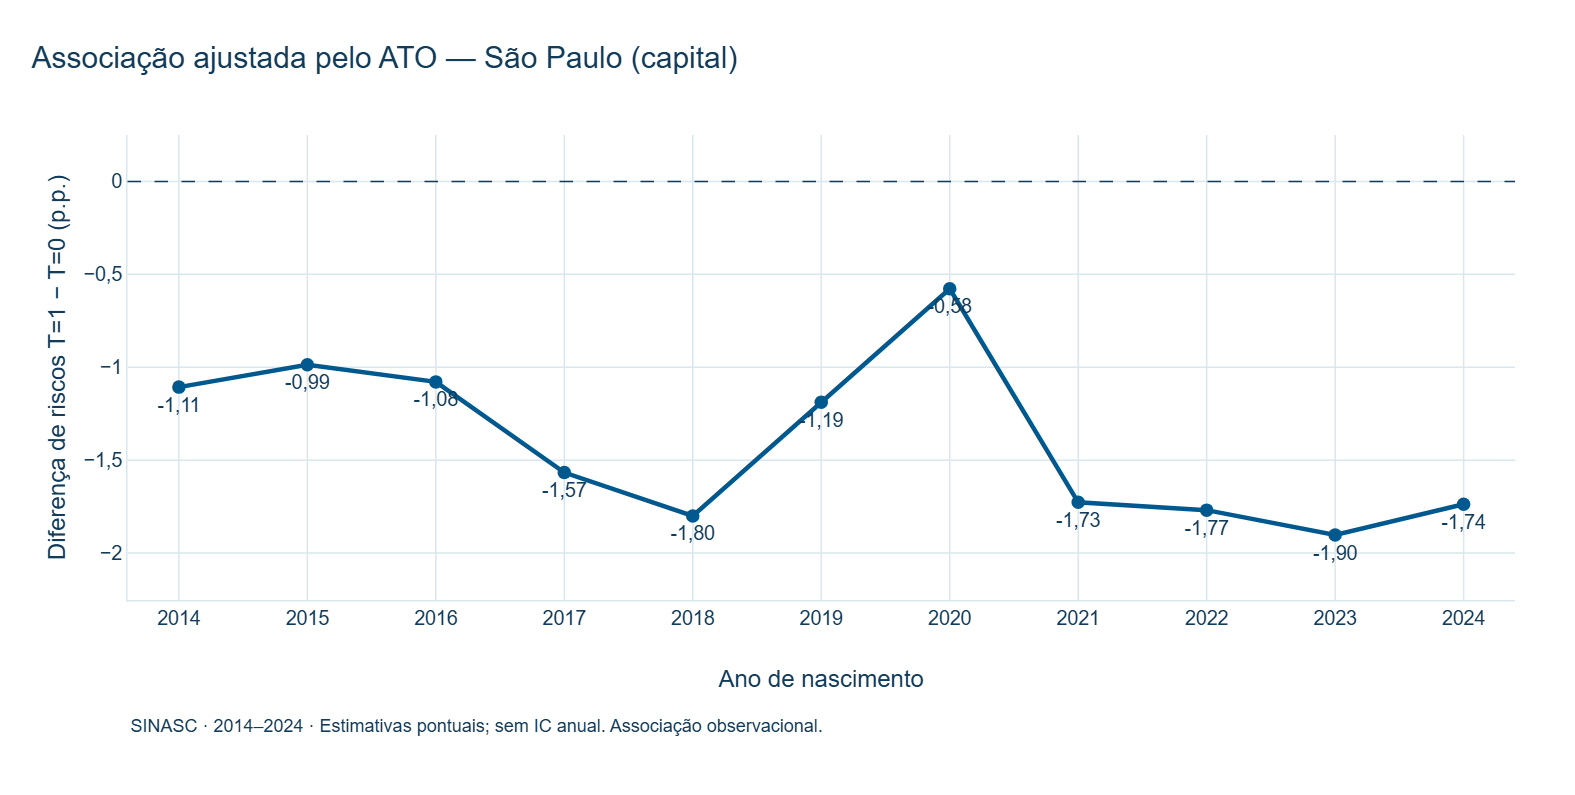

In [14]:
fig_ato = go.Figure(go.Scatter(
    x=ANOS, y=resultados.dif_ato_pp.tolist(), mode="lines+markers+text", connectgaps=False,
    text=[fmt(v, 2) for v in resultados.dif_ato_pp], textposition="bottom center",
    line=dict(color=CORES_IPT["AZUL_PRINCIPAL"], width=3),
    marker=dict(size=9, symbol="circle"), cliponaxis=False,
    customdata=resultados[["n_t1", "n_t0", "ess1", "ess0"]].values.tolist(),
    hovertemplate="Ano %{x}<br>Diferença ATO: %{y:.3f} p.p.<br>T=1: %{customdata[0]:,.0f}"
        "<br>T=0: %{customdata[1]:,.0f}<br>ESS T=1: %{customdata[2]:,.0f}"
        "<br>ESS T=0: %{customdata[3]:,.0f}<extra></extra>"))
aplicar_tema_base(fig_ato, "Associação ajustada pelo ATO — São Paulo (capital)")
fig_ato.add_hline(y=0, line=dict(color=CORES_IPT["AZUL_ESCURO"], dash="dash", width=1))
fig_ato.update_layout(width=1050, height=530, separators=",.", showlegend=False,
    margin=dict(l=85, r=40, t=90, b=130))
fig_ato.update_xaxes(title="Ano de nascimento", tickmode="array", tickvals=ANOS,
                    tickformat="d", range=[2013.6, 2024.4])
fig_ato.update_yaxes(title="Diferença de riscos T=1 − T=0 (p.p.)",
    range=[min(-0.3, resultados.dif_ato_pp.min() - 0.35), max(0.25, resultados.dif_ato_pp.max() + 0.35)])
fig_ato.add_annotation(x=0, y=-0.30, xref="paper", yref="paper", xanchor="left", showarrow=False,
    text="SINASC · 2014–2024 · Estimativas pontuais; sem IC anual. Associação observacional.", font=dict(size=12))
exibir_plotly(fig_ato)

## 6. Composição dos grupos

T=0 corresponde a início nos meses 4–6. Denominador: todos os nascimentos elegíveis do respectivo ano. Mudanças desta proporção também mudam a composição da população enfatizada pelos pesos ATO.

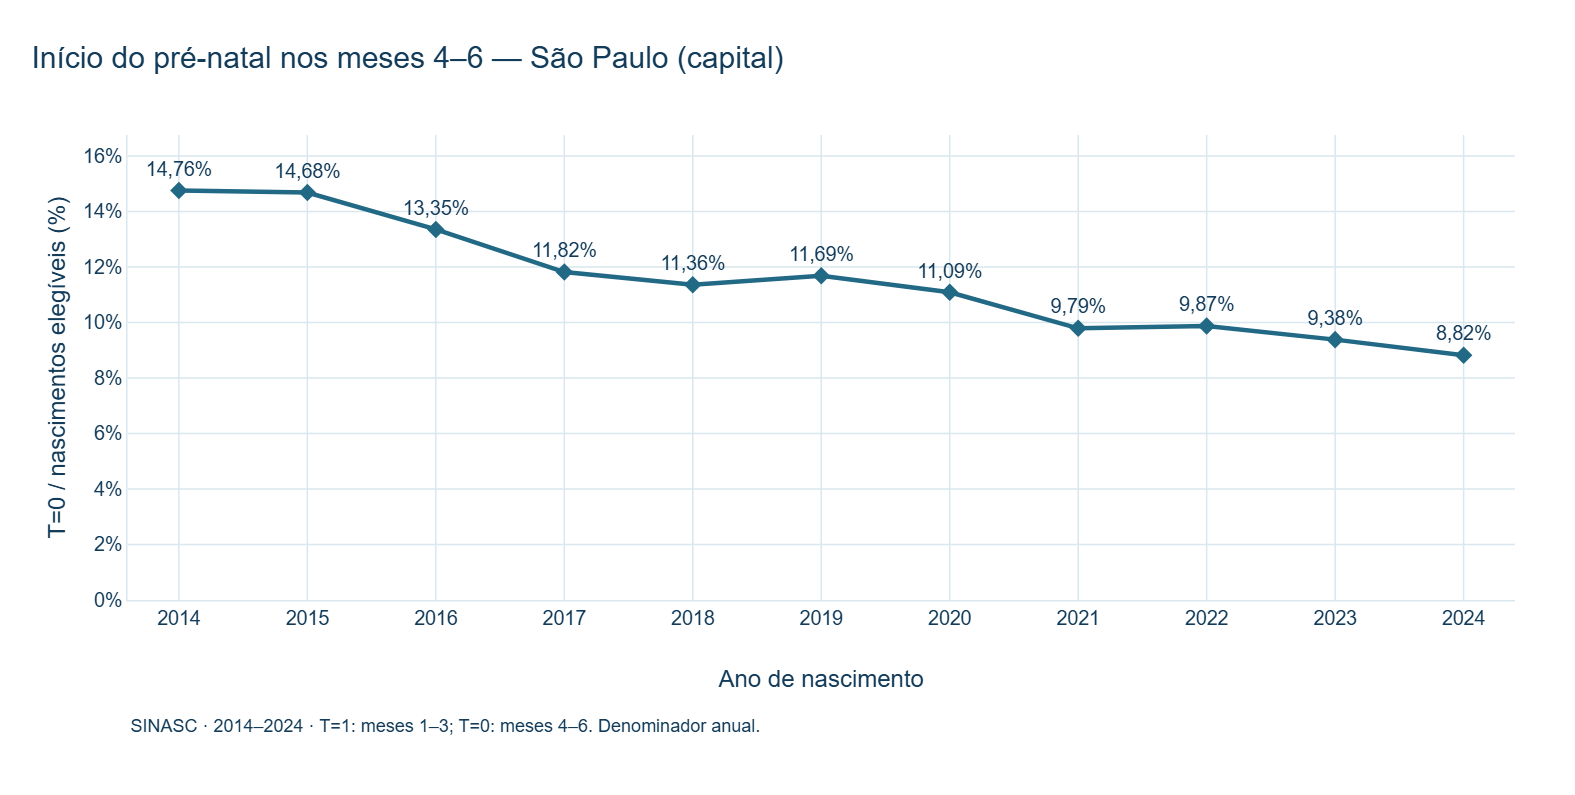

In [15]:
fig_grupos = go.Figure(go.Scatter(
    x=ANOS, y=resultados.pct_t0.tolist(), mode="lines+markers+text", connectgaps=False,
    text=[fmt(v, 2) + "%" for v in resultados.pct_t0], textposition="top center",
    line=dict(color=CORES_IPT["AZUL_MEDIO"], width=3), marker=dict(size=9, symbol="diamond"),
    customdata=resultados[["n_t0", "n"]].values.tolist(), cliponaxis=False,
    hovertemplate="Ano %{x}<br>T=0 entre elegíveis: %{y:.2f}%<br>T=0: %{customdata[0]:,.0f}"
        "<br>Elegíveis: %{customdata[1]:,.0f}<extra></extra>"))
aplicar_tema_base(fig_grupos, "Início do pré-natal nos meses 4–6 — São Paulo (capital)")
fig_grupos.update_layout(width=1050, height=530, separators=",.", showlegend=False,
    margin=dict(l=85, r=40, t=90, b=130))
fig_grupos.update_xaxes(title="Ano de nascimento", tickmode="array", tickvals=ANOS,
                       tickformat="d", range=[2013.6, 2024.4])
fig_grupos.update_yaxes(title="T=0 / nascimentos elegíveis (%)", ticksuffix="%",
                       range=[0, resultados.pct_t0.max() + 2], dtick=2)
fig_grupos.add_annotation(x=0, y=-0.30, xref="paper", yref="paper", xanchor="left", showarrow=False,
    text="SINASC · 2014–2024 · T=1: meses 1–3; T=0: meses 4–6. Denominador anual.", font=dict(size=12))
exibir_plotly(fig_grupos)

## 7. Interpretação dos resultados

Valores calculados a partir desta execução. Variações de magnitude são descritivas, sem teste de diferenças temporais.

A série oscila: 2014–2016 ficam próximos de −1 p.p.; 2017–2018 apresentam magnitudes maiores, há aproximação de zero em 2019–2020 e retorno a diferenças mais negativas em 2021–2024. **2024 é semelhante a 2021–2022 e menos negativo que 2023 em 0,17 p.p.** Isso não demonstra mudança causal nem significância temporal. A proporção T=0 cai no período, com pequenas reversões em 2019 e 2022; portanto, também não é uma queda estritamente monotônica.

In [16]:
estimados = resultados.loc[validos]
inicial, final = resultados.loc[2014], resultados.loc[2024]
ano_min, ano_max = estimados.dif_ato_pp.idxmin(), estimados.dif_ato_pp.idxmax()
falhas = resultados.index[~validos].tolist()
display(Markdown(f"""
- **Direção:** diferença ATO negativa em **{int(estimados.dif_ato_pp.lt(0).sum())} de {len(estimados)} anos estimados**. A faixa vai de **{fmt(estimados.dif_ato_pp.min(), 2)} p.p. ({ano_min})** a **{fmt(estimados.dif_ato_pp.max(), 2)} p.p. ({ano_max})**, amplitude de {fmt(estimados.dif_ato_pp.max() - estimados.dif_ato_pp.min(), 2)} p.p.
- **2024:** ATO **{fmt(final.dif_ato_pp, 2)} p.p.**, compatível com o notebook 06; diferença bruta {fmt(final.dif_bruta_pp, 2)} p.p. Em relação a 2023, a estimativa muda {fmt(final.dif_ato_pp - resultados.loc[2023, 'dif_ato_pp'], 2)} p.p. Não se conclui diferença estatisticamente significativa.
- **Composição:** T=0 passa de **{fmt(inicial.pct_t0, 2)}%** em 2014 a **{fmt(final.pct_t0, 2)}%** em 2024 ({fmt(final.pct_t0 - inicial.pct_t0, 2)} p.p.). T=0 cai de {fmt(inicial.n_t0)} a {fmt(final.n_t0)} ({fmt(100 * (final.n_t0 / inicial.n_t0 - 1), 2)}%); T=1, de {fmt(inicial.n_t1)} a {fmt(final.n_t1)} ({fmt(100 * (final.n_t1 / inicial.n_t1 - 1), 2)}%). Elegíveis: {fmt(inicial.n)} → {fmt(final.n)}.
- **ESS:** T=1 varia de {fmt(estimados.ess1.min())} a {fmt(estimados.ess1.max())}; T=0, de {fmt(estimados.ess0.min())} a {fmt(estimados.ess0.max())}. Retenção efetiva mínima: {fmt(diagnosticos.ess_rel_t1_pct.min(), 1)}% em T=1 e {fmt(diagnosticos.ess_rel_t0_pct.min(), 1)}% em T=0. Isso descreve perda por ponderação, sem garantir precisão dos contrastes ou de subgrupos.
- **Balanço:** maior |SMD| após ATO entre termos ajustados = **{fmt(diagnosticos.smd_depois_max.max(), 4)}**. Para situação conjugal, fora do modelo, o máximo anual varia de **{fmt(diagnosticos.smd_conjugal_max.min(), 3)} a {fmt(diagnosticos.smd_conjugal_max.max(), 3)}**; o desequilíbrio residual permanece explícito.
- **Suporte e execução:** maior participação de observações fora do suporte na massa de pesos = {fmt(diagnosticos[['fora_peso_t1_pct', 'fora_peso_t0_pct']].max().max(), 4)}%; maior participação individual = {fmt(diagnosticos[['max_participacao_t1_pct', 'max_participacao_t0_pct']].max().max(), 4)}%. Anos sem estimativa: {falhas or 'nenhum'}. As três idades fora de faixa receberam somente a imputação autorizada.
"""))


- **Direção:** diferença ATO negativa em **11 de 11 anos estimados**. A faixa vai de **-1,90 p.p. (2023)** a **-0,58 p.p. (2020)**, amplitude de 1,33 p.p.
- **2024:** ATO **-1,74 p.p.**, compatível com o notebook 06; diferença bruta -2,00 p.p. Em relação a 2023, a estimativa muda 0,17 p.p. Não se conclui diferença estatisticamente significativa.
- **Composição:** T=0 passa de **14,76%** em 2014 a **8,82%** em 2024 (-5,94 p.p.). T=0 cai de 24.348 a 10.118 (-58,44%); T=1, de 140.639 a 104.576 (-25,64%). Elegíveis: 164.987 → 114.694.
- **ESS:** T=1 varia de 84.995 a 112.037; T=0, de 10.096 a 24.155. Retenção efetiva mínima: 77,4% em T=1 e 99,2% em T=0. Isso descreve perda por ponderação, sem garantir precisão dos contrastes ou de subgrupos.
- **Balanço:** maior |SMD| após ATO entre termos ajustados = **0,0070**. Para situação conjugal, fora do modelo, o máximo anual varia de **0,184 a 0,207**; o desequilíbrio residual permanece explícito.
- **Suporte e execução:** maior participação de observações fora do suporte na massa de pesos = 0,0329%; maior participação individual = 0,0108%. Anos sem estimativa: nenhum. As três idades fora de faixa receberam somente a imputação autorizada.


## 8. Limitações e próxima etapa

- **Associação, não causalidade identificada:** confundimento não observado, registro retrospectivo, temporalidade imperfeita das covariáveis e seleção de nascidos vivos permanecem. Bom balanço dos termos do escore não resolve esses problemas; situação conjugal mostra desequilíbrio em variável não ajustada.
- **População-alvo variável:** o ATO enfatiza perfis diferentes conforme a distribuição anual das covariáveis e do escore. A série não representa efeitos em população fixa. A mudança anual não pode ser atribuída ao início do pré-natal ou a eventos externos.
- **Incerteza não estimada nesta etapa:** não há IC para todos os anos nem teste de diferença entre anos. O IC de 2024 pertence ao notebook 06 e não foi recalculado. ESS elevado não comprova poder adequado; correlação entre nascimentos/estabelecimentos e mães recorrentes não é avaliada.
- **Mensuração e ausentes:** regras operacionais preservadas, sem comprovar invariância histórica dos campos. “Ignorado” é indicador de ausência; perdas fetais misturam perdas e abortos. A imputação dos três registros de idade é documentada e autorizada; os indicadores raros podem reter algum desequilíbrio por penalização.
- **Próxima etapa recomendada, sujeita à validação manual:** planejar a quantificação de incerteza anual e de contrastes temporais, com atenção à redução de T=0 e à comparabilidade da população de sobreposição, antes de afirmar mudança temporal ou interpretar causalmente. Nenhum novo experimento é iniciado aqui.

**Artefato:** este notebook executado. Resultados na granularidade ano (chave `Ano`); balanço detalhado em memória na chave `(ano, variavel, nivel)`. As tabelas e os gráficos preservam resultados e diagnósticos sem exportações auxiliares.

In [17]:
assert not balanco.duplicated(["ano", "variavel", "nivel"]).any()
for arquivo, assinatura in assinaturas.items():
    assert hashlib.sha256((raiz / arquivo).read_bytes()).hexdigest() == assinatura, arquivo
for figura, coluna in [(fig_ato, "dif_ato_pp"), (fig_grupos, "pct_t0")]:
    assert list(figura.data[0].x) == ANOS
    np.testing.assert_allclose(np.asarray(figura.data[0].y, float), resultados[coluna].to_numpy(float), equal_nan=True)
    assert figura.data[0].error_y.array is None
print(f"Concluído: {validos.sum()}/11 anos estimados, tabelas anuais e dois gráficos. "
      "Fontes metodológicas preservadas; sem exportações auxiliares.")

Concluído: 11/11 anos estimados, tabelas anuais e dois gráficos. Fontes metodológicas preservadas; sem exportações auxiliares.
